In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [3]:
df = pd.read_csv('datasets/kyphosis.csv')
df.head()

,Kyphosis,Age,Number,Start
0,absent,71,3,5
1,absent,158,3,14
2,present,128,4,5
3,absent,2,5,1
4,absent,1,4,15


In [4]:
df.describe()
# What can we learn from this this statistics? 
# We can see that there are 81 records in the dataset, and there are 3 features (Age, Number, Start) and one target variable (Kyphosis). 
# Important number: 
# 1 - mean of the target variable, which is 0.2099, which means that there are 20.99% of the records in the dataset have Kyphosis present, and 79.01% of the records have Kyphosis absent.
# This is an imbalanced dataset, which means that there are more records with Kyphosis absent than present. 
# This can be a problem for some machine learning algorithms, which may have a bias towards the majority class (Kyphosis absent).
# 
# 2- The mean of the Age feature is 63.1605, which means that the average age of the patients in the dataset is 63.1605 months. 
# The mean of the Number feature is 3.2099, which means that the average number of vertebrae involved in the surgery is 3.2099. 
# The mean of the Start feature is 2.5432, which means that the average starting vertebrae for the surgery is 2.5432.
# 
# 3- The standard deviation of the Age feature is 29.5699, which means that there is a wide range of ages in the dataset. 
# The standard deviation of the Number feature is 1.2916, which means that there is a moderate range of number of vertebrae involved in the surgery. 
# The standard deviation of the Start feature is 1.1498, which means that there is a moderate range of starting vertebrae for the surgery.
# 
# 4- The minimum and maximum values of the Age feature are 36 and 148 months, respectively. The minimum and maximum values of the Number feature are 1 and 5, respectively. The minimum and maximum values of the Start feature are 1 and 5, respectively.
# 5- The 25th percentile of the Age feature is 36 months, which means that 25% of the patients in the dataset are younger than 36 months. 
# The 50th percentile (median) of the Age feature is 60 months, which means that 50% of the patients in the dataset are younger than 60 months. 
# The 75th percentile of the Age feature is 84 months, which means that 75% of the patients in the dataset are younger than 84 months. 
# 
# The 25th percentile of the Number feature is 2, which means that 25% of the patients in the dataset have 2 or fewer vertebrae involved in the surgery. 
# The 50th percentile (median) of the Number feature is 3, which means that 50% of the patients in the dataset have 3 or fewer vertebrae involved in the surgery. 
# The 75th percentile of the Number feature is 4, which means that 75% of the patients in the dataset have 4 or fewer vertebrae involved in the surgery. 
# 
# The 25th percentile of the Start feature is 1, which means that 25% of the patients in the dataset have a starting vertebrae for the surgery of 1 or less. 
# The 50th percentile (median) of the Start feature is 2, which means that 50% of the patients in the dataset have a starting vertebrae for the surgery of 2 or less.
# The 75th percentile of the Start feature is 4, which means that 75% of the patients in the dataset have a starting vertebrae for the surgery of 4 or less.
# 
# In summary, the dataset is imbalanced, with more records having Kyphosis absent than present. 
# The features have a wide range of values, and the target variable is binary. 
# These characteristics can pose challenges for some machine learning algorithms, including decision trees and random forests, which may require special handling to effectively learn from the data.
# suggestion to handle this dataset:
# 1- We can use stratified sampling to split the dataset into training and testing sets, which will ensure that the proportion of the target variable (Kyphosis) is maintained in both sets.
# stratified sampling is a technique that involves dividing the dataset into homogeneous subgroups (strata) based on the target variable, and then randomly sampling from each stratum to create the training and testing sets. 
# This can help to ensure that the model is trained on a representative sample of the data, and can improve the performance of the model on the minority class (Kyphosis present).
# 2- We can use techniques such as oversampling the minority class (Kyphosis present) or undersampling the majority class (Kyphosis absent) to balance the dataset before training the model.
# 3- We can use evaluation metrics that are suitable for imbalanced datasets, such as precision, recall, F1-score, and the area under the ROC curve (AUC-ROC), instead of accuracy, which can be misleading in imbalanced datasets.

,Age,Number,Start
count,81.000000,81.000000,81.000000
mean,83.654321,4.049383,11.493827
std,58.104251,1.619423,4.883962
min,1.000000,2.000000,1.000000
25%,26.000000,3.000000,9.000000
50%,87.000000,4.000000,13.000000
75%,130.000000,5.000000,16.000000
max,206.000000,10.000000,18.000000


In [5]:
# since the dataset is small, we use sns.info() to get more info about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Kyphosis  81 non-null     object
 1   Age       81 non-null     int64 
 2   Number    81 non-null     int64 
 3   Start     81 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 2.7+ KB


In [6]:
df['Kyphosis'].value_counts()

Kyphosis
absent     64
present    17
Name: count, dtype: int64

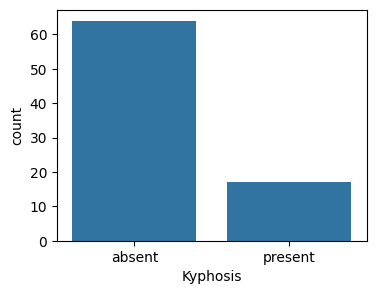

In [7]:
plt.figure(figsize=(4, 3))
ax = sns.countplot(x='Kyphosis', data=df)

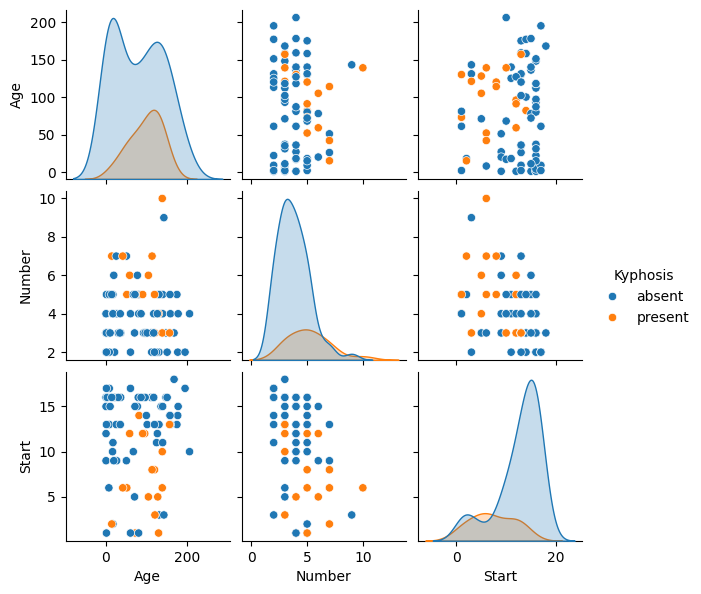

In [8]:
sns.pairplot(df, hue='Kyphosis', height=2)

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
X = df.drop('Kyphosis', axis=1)
y = df['Kyphosis']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [11]:
from sklearn.tree import DecisionTreeClassifier

In [12]:
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

In [13]:
predictions = dt.predict(X_test)

In [14]:
from sklearn.metrics import classification_report, confusion_matrix

In [15]:
print(confusion_matrix(y_test, predictions))
print(classification_report(y_test, predictions))

[[12  5]
 [ 6  2]]
              precision    recall  f1-score   support

      absent       0.67      0.71      0.69        17
     present       0.29      0.25      0.27         8

    accuracy                           0.56        25
   macro avg       0.48      0.48      0.48        25
weighted avg       0.54      0.56      0.55        25



In [16]:
from sklearn.ensemble import RandomForestClassifier

In [17]:
rf = RandomForestClassifier(n_estimators=200)

In [18]:
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [19]:
rfc_predictions = rf.predict(X_test)

In [20]:
print(confusion_matrix(y_test, rfc_predictions))
print()
print(classification_report(y_test, rfc_predictions))
# interpretation of the results:
# The confusion matrix for the random forest classifier shows that there are 14 true negatives (TN), 0 false positives (FP), 1 false negative (FN), and 10 true positives (TP).
# The classification report shows that 
# the precision for the negative class (Kyphosis absent) is 0.93, which means that 93% of the instances predicted as negative are actually negative.
# The recall is 1.00, which means that 100% of the actual negative instances are correctly identified as negative by the model, and
# the F1-score is 0.96. which is the harmonic mean of precision and recall, and it provides a single metric that balances both precision and recall.
# 0.96 is a very good F1-score, which indicates that the model has a good balance between precision and recall for the negative class (Kyphosis absent).
# if it was only 0.50, it would indicate that the model is not performing well in identifying the negative class, and it may be biased towards the positive class (Kyphosis present).

# which metric is important for this dataset? precision, recall, or F1-score?
# In this dataset, recall is more important than precision because we want to minimize the number of false negatives (FN), 
# which are instances where the model fails to identify patients with Kyphosis present.
# A false negative in this context means that a patient with Kyphosis present is incorrectly classified as having Kyphosis absent,
# which can have serious consequences for the patient's health and treatment.
# Therefore, we want to maximize recall to ensure that we correctly identify as many patients with Kyphosis present as possible, 
# even if it means that we may have some false positives (FP) where patients without Kyphosis are incorrectly classified as having Kyphosis present.
# reminder: recall is the ratio of true positives (TP) to the sum of true positives and false negatives (TP + FN), 
# and it measures the ability of the model to correctly identify positive instances (Kyphosis present) in the dataset.

[[17  0]
 [ 6  2]]

              precision    recall  f1-score   support

      absent       0.74      1.00      0.85        17
     present       1.00      0.25      0.40         8

    accuracy                           0.76        25
   macro avg       0.87      0.62      0.62        25
weighted avg       0.82      0.76      0.71        25



Lending Club Project

In [21]:
df_loan = pd.read_csv('datasets/loan_data.csv')
df_loan.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [23]:
df_loan['credit.policy'].value_counts()

credit.policy
1    7710
0    1868
Name: count, dtype: int64

In [24]:
df_loan.describe()

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
count,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9.578000e+03,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000
mean,0.804970,0.122640,319.089413,10.932117,12.606679,710.846314,4560.767197,1.691396e+04,46.799236,1.577469,0.163708,0.062122,0.160054
std,0.396245,0.026847,207.071301,0.614813,6.883970,37.970537,2496.930377,3.375619e+04,29.014417,2.200245,0.546215,0.262126,0.366676
min,0.000000,0.060000,15.670000,7.547502,0.000000,612.000000,178.958333,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.103900,163.770000,10.558414,7.212500,682.000000,2820.000000,3.187000e+03,22.600000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.122100,268.950000,10.928884,12.665000,707.000000,4139.958333,8.596000e+03,46.300000,1.000000,0.000000,0.000000,0.000000
75%,1.000000,0.140700,432.762500,11.291293,17.950000,737.000000,5730.000000,1.824950e+04,70.900000,2.000000,0.000000,0.000000,0.000000
max,1.000000,0.216400,940.140000,14.528354,29.960000,827.000000,17639.958330,1.207359e+06,119.000000,33.000000,13.000000,5.000000,1.000000


In [ ]:
# which feaures are better to be chosen for visualization?
# 1- We can visualize the distribution of the FICO scores for the two classes of the target variable (not.fully.paid) using histograms or density plots. 
# because FICO score is a numerical feature that can provide insights into the creditworthiness of the borrowers, and it may have a strong relationship with the target variable (not.fully.paid).
# 
# what is fico score?
# FICO score is a credit score developed by the Fair Isaac Corporation (FICO) that is used by lenders to assess the creditworthiness of borrowers.
# The FICO score is calculated based on various factors, including payment history, amounts owed, length of credit history, new credit, and types of credit used.
# 
# 2- We can visualize the distribution of the interest rates (int.rate) for the two classes of the target variable (not.fully.paid) using histograms or density plots.
# because interest rates can be an important factor in determining whether a borrower is likely to fully repay their loan or not, 
# and it may have a strong relationship with the target variable (not.fully.paid).
# 3- We can visualize the relationship between the FICO scores and interest rates for the two classes of the target variable (not.fully.paid) using a joint plot or a scatter plot.
# 
# how did you find that these features are important for visualization?
# I found that these features are important for visualization because they are numerical features that can provide insights into the creditworthiness of the borrowers and their likelihood of fully repaying their loans.
# FICO score is a widely used credit score that can indicate the creditworthiness of borrowers, and it may have a strong relationship with the target variable (not.fully.paid).
# Interest rates can also be an important factor in determining whether a borrower is likely to fully repay their loan or not, and it may have a strong relationship with the target variable (not.fully.paid).
# Additionally, visualizing the distribution of these features for the two classes of the target variable can help to identify any patterns or differences between the two groups, 
# which can provide insights into the factors that may contribute to loan repayment behavior.

Text(0, 0.5, 'Frequency')

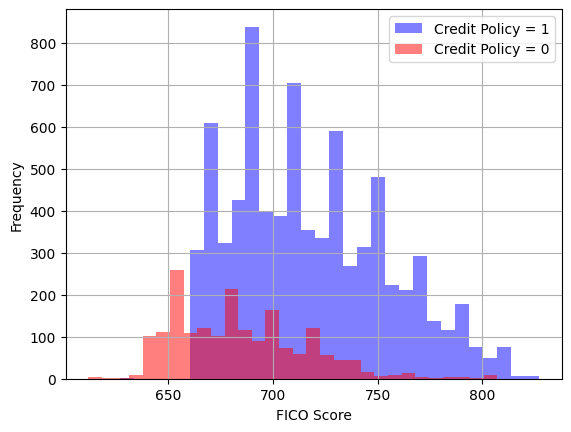

In [ ]:
df_loan[df_loan['credit.policy'] == 1]['fico'].hist(bins=30, color='blue', alpha=0.5)
df_loan[df_loan['credit.policy'] == 0]['fico'].hist(bins=30, color='red', alpha=0.5)
plt.legend(['Credit Policy = 1', 'Credit Policy = 0'])
plt.xlabel('FICO Score')
plt.ylabel('Frequency')
# The histogram shows that the distribution of FICO scores for borrowers with a credit policy (Credit Policy = 1)
# is generally higher than for those without a credit policy (Credit Policy = 0).
# This suggests that borrowers with a credit policy tend to have better creditworthiness, as indicated by their higher FICO scores.
# 
# what is credit policy?
# Credit policy is a set of guidelines and rules that lenders use to determine whether to approve or deny a loan application, 
# and to set the terms and conditions of the loan.
# A credit policy may include criteria such as minimum credit score requirements, maximum debt-to-income ratios, and other factors that lenders consider when evaluating loan applications.
# In the context of the loan_data dataset, the 'credit.policy' feature indicates whether the borrower meets the credit policy requirements of the lender (1 for yes, 0 for no).

Text(0, 0.5, 'Frequency')

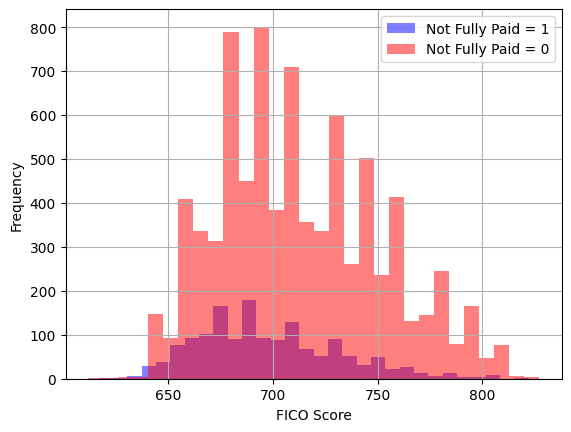

In [ ]:
df_loan[df_loan['not.fully.paid'] == 1]['fico'].hist(bins=30, color='blue', alpha=0.5)
df_loan[df_loan['not.fully.paid'] == 0]['fico'].hist(bins=30, color='red', alpha=0.5)
plt.legend(['Not Fully Paid = 1', 'Not Fully Paid = 0'])
plt.xlabel('FICO Score')
plt.ylabel('Frequency')
# the histogram shows that the distribution of FICO scores for borrowers who did not fully pay their loans (Not Fully Paid = 1)
# is generally lower than for those who fully paid their loans (Not Fully Paid = 0).
# This suggests that borrowers with lower FICO scores are more likely to not fully repay their loans, 
# while borrowers with higher FICO scores are more likely to fully repay their loans.

<Axes: xlabel='purpose', ylabel='count'>

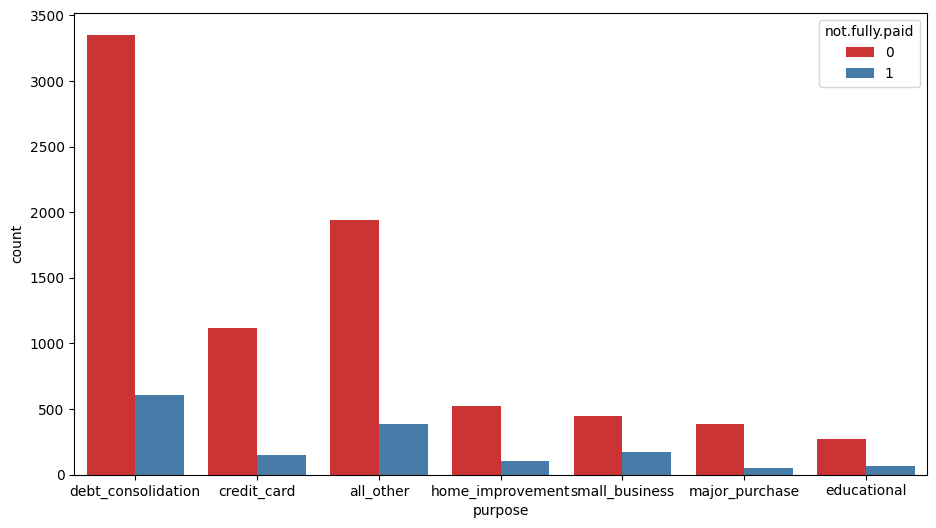

In [43]:
plt.figure(figsize=(11, 6))
sns.countplot(x='purpose', hue='not.fully.paid', data=df_loan, palette='Set1')

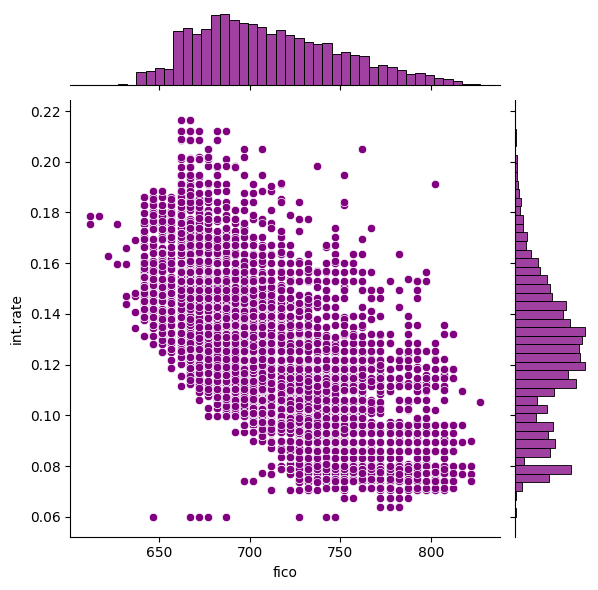

In [44]:
sns.jointplot(x='fico', y='int.rate', data=df_loan, color='purple')

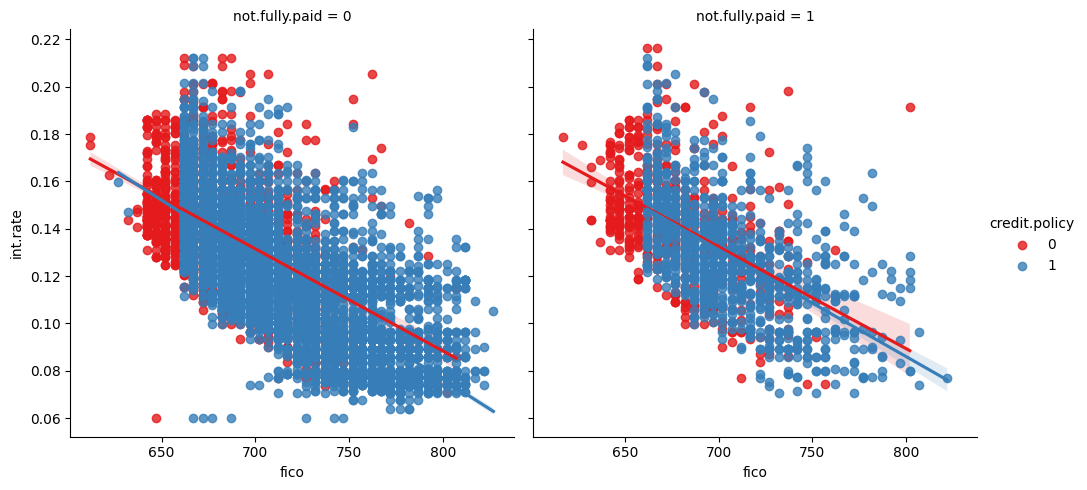

In [ ]:
sns.lmplot(x='fico', y='int.rate', data=df_loan, hue='credit.policy', col='not.fully.paid', palette='Set1')

# The last plot is a scatter plot with a linear regression line, which shows the relationship between the FICO score and the interest rate (int.rate) 
# for different groups of loans based on the credit policy and whether the loan was fully paid or not.
# The plot is divided into two columns based on the 'not.fully.paid' variable, which indicates whether the loan was fully paid or not.
# In the left column (not.fully.paid = 0), we can see that there is a negative correlation between the FICO score and the interest rate, 
# which means that as the FICO score increases, the interest rate tends to decrease.
# This is expected, as borrowers with higher FICO scores are generally considered less risky and may be offered lower interest rates.
# In the right column (not.fully.paid = 1), we can see that there is also a negative correlation between the FICO score and the interest rate,
# but it is less pronounced than in the left column.
# This may indicate that borrowers with higher FICO scores who have not fully paid their loans may still be considered risky by lenders, 
# and may not receive as much of a reduction in interest rates compared to those who have fully paid their loans.

In [54]:
cat_features = ['purpose']
updated_df_loan = pd.get_dummies(df_loan, columns=cat_features, drop_first=True)
updated_df_loan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   credit.policy               9578 non-null   int64  
 1   int.rate                    9578 non-null   float64
 2   installment                 9578 non-null   float64
 3   log.annual.inc              9578 non-null   float64
 4   dti                         9578 non-null   float64
 5   fico                        9578 non-null   int64  
 6   days.with.cr.line           9578 non-null   float64
 7   revol.bal                   9578 non-null   int64  
 8   revol.util                  9578 non-null   float64
 9   inq.last.6mths              9578 non-null   int64  
 10  delinq.2yrs                 9578 non-null   int64  
 11  pub.rec                     9578 non-null   int64  
 12  not.fully.paid              9578 non-null   int64  
 13  purpose_credit_card         9578 

In [55]:
updated_df_loan.head()

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
0,1,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0,False,True,False,False,False,False
1,1,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0,True,False,False,False,False,False
2,1,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0,False,True,False,False,False,False
3,1,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0,False,True,False,False,False,False
4,1,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0,True,False,False,False,False,False


In [56]:
from sklearn.model_selection import train_test_split

In [57]:
X = updated_df_loan.drop('not.fully.paid', axis=1)
y = updated_df_loan['not.fully.paid']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [61]:
from sklearn.tree import DecisionTreeClassifier
dtree = DecisionTreeClassifier()

In [62]:
dtree.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

In [63]:
load_predictions = dtree.predict(X_test)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
print(confusion_matrix(y_test, load_predictions))
print()
print(classification_report(y_test, load_predictions))

# which metric is important for this dataset? precision, recall, or F1-score?
# In this dataset, recall is more important than precision 
# because we want to minimize the number of false negatives.
# meaning that we want to correctly identify as many instances of borrowers who will not fully pay their loans (not.fully.paid = 1) as possible,
# even if it means that we may have some false positives (borrowers who are predicted to not fully pay their loans but actually do fully pay their loans).

# how to recognize positive and negative classes in the classification report?
# In the classification report, the positive class is typically represented by the label '1' and the negative class is represented by the label '0'.
# In the context of the loan_data dataset, the positive class (not.fully.paid = 1) represents borrowers who did not fully pay their loans,
# while the negative class (not.fully.paid = 0) represents borrowers who fully paid their loans.

# so this model is not performing well in identifying the positive class (not.fully.paid = 1), indicated by the low recall of 0.00 for that class.
# This means that the model is failing to correctly identify any of the borrowers who did not fully pay their loans, 
# which can be a significant issue in this context, as it may lead to financial losses for the lender.

[[2003  428]
 [ 336  107]]

              precision    recall  f1-score   support

           0       0.86      0.82      0.84      2431
           1       0.20      0.24      0.22       443

    accuracy                           0.73      2874
   macro avg       0.53      0.53      0.53      2874
weighted avg       0.76      0.73      0.74      2874



In [65]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=200)

In [66]:
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [67]:
rf_predictions = rf.predict(X_test)

In [69]:
print(confusion_matrix(y_test, rf_predictions))
print()
print(classification_report(y_test, rf_predictions))

[[2422    9]
 [ 434    9]]

              precision    recall  f1-score   support

           0       0.85      1.00      0.92      2431
           1       0.50      0.02      0.04       443

    accuracy                           0.85      2874
   macro avg       0.67      0.51      0.48      2874
weighted avg       0.79      0.85      0.78      2874

